# 13 - Attributing the Tomasov CNN Gap: Protocol or Reconstruction?

## The objection (R2C3)

Our reconstruction of the Tomasov CNN reaches **68.74%** accuracy. Their paper reports
**85.47%** for the same RDFT front end. We assert that the 16.73-point difference is an
artefact of *evaluation protocol* - they split randomly over windows that overlap by
96.9%, we split in contiguous blocks with guard bands. But asserting it is not showing
it. The gap could equally mean our reconstruction is simply worse than theirs, in which
case the whole baseline comparison is unsafe.

## The design

One architecture, one front end, one training recipe. Only the **partition** changes.

| Arm | Population | Partition | What it isolates |
|---|---|---|---|
| **A** | final manifest (guarded, decimated) | our blocked spatio-temporal split | reference - must reproduce 68.74% |
| **B** | *exactly the same rows as A* | stratified **random** split | protocol effect at our 2048 stride |
| **C** | same annotation footprint re-windowed at **stride 256** | stratified random split | additional effect of their finer stride |

Arms A and B share one loaded feature matrix, so the only difference between them is
which rows are called `train` and which `test`. Nothing else - not the model, not the
seed, not the class balance, not a single sample of raw data - is allowed to vary.

Arm C then adds the one remaining protocol difference: their stride of 256 samples
produces windows overlapping by 96.9% rather than 75%, so a random split places
near-duplicate windows on both sides of the partition.

## Reading the outcome

Write the residual as the published accuracy minus arm C. That residual is the part of
the gap that protocol **cannot** explain, and it is the honest measure of reconstruction
fidelity.

| Result | What the paper must say |
|---|---|
| arm C near 85% (small residual) | The reconstruction is faithful; the gap is protocol. Our claim stands as written. |
| arm C clearly above arm A but well short of 85% | Protocol explains part of it. Report both components and stop calling the baseline comparison exact. |
| arm C near arm A | Protocol explains nothing. The reconstruction is the problem and the baseline must be withdrawn or refitted. |

## Cost

Three training runs of the same size as notebook 11 (about 26 minutes each on the Jetson
at `DENSE_UNITS=1024`), plus two passes over the HDF5 files. Budget roughly two hours.

In [1]:
import sys, json, time, gc
from pathlib import Path
# No machine-specific path: the kernel starts in Experiment/ (or the repo root).
EXPERIMENT_DIR = Path.cwd() if (Path.cwd() / "dasfe").is_dir() else Path.cwd() / "Experiment"
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from dasfe import config as C, baselines as B, evaluate as EV, preprocess as pp

sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURE ME -----------------------------
TRANSFORM   = "rdft"     # the front end whose published number we are matching
DENSE_UNITS = 1024       # 1024 reproduces the 68.74% reference in notebook 11
EPOCHS      = 30
BATCH       = 256
LR          = 1e-4
STRIDE_C    = 256        # their stride, Section III-B of the Access paper
RUN_ARMS    = ("A_blocked", "B_random_2048", "C_random_256")
MAX_GB      = 10.0
# ------------------------------------------------------------------------

SUBOFFSETS = C.WIN_HOP // STRIDE_C          # 2048 / 256 = 8 windows per parent

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "")

spec = C.TOMASOV
out_dir = C.results_dir("tomasov", "13_protocol_attribution")
mani = pd.read_parquet(C.results_dir("tomasov", "01_splits") / "split_manifest.parquet")
CLASSES = sorted(mani.label.unique())

ref_dir = C.results_dir("tomasov", "10_cnn_baseline")
published = pd.read_csv(ref_dir / "tomasov_published_reference.csv")
PUB = published[published.preproc.str.lower() == TRANSFORM].iloc[0]
PUB_ACC, PUB_F1 = float(PUB["accuracy"]), float(PUB["f1_macro"])

print(f"{len(mani):,} windows | {len(CLASSES)} classes")
print(f"published {TRANSFORM.upper()} reference: acc {PUB_ACC:.2f}%  F1 {PUB_F1:.2f}%")
print(f"arm C re-windows at stride {STRIDE_C} -> {SUBOFFSETS} windows per parent")
print("output:", out_dir)

device: cuda | Orin
172,458 windows | 9 classes
published RDFT reference: acc 85.47%  F1 84.84%
arm C re-windows at stride 256 -> 8 windows per parent
output: /mnt/b6bdcd1c-136a-435b-aeed-0e1b31c32749/Paper_Reeyan/Results/tomasov/13_protocol_attribution


## 1. Build the three partitions

Arms A and B are *the same rows*. Arm A carries the stored blocked assignment; arm B
reassigns those same rows at random, stratified by class so the class proportions are
unchanged and the only difference is where the cut falls in time.

Arm C expands each sampled parent window into `SUBOFFSETS` windows spaced `STRIDE_C`
samples apart, which reproduces their window density. Per-class parent counts are set to
the class count divided by `SUBOFFSETS` so the expanded population matches the final
manifest in both total size and class proportions - otherwise arm C would differ from arm
B in two ways at once.

**Documented approximation.** A sub-offset window inherits the label of its parent. The
released annotation is a block mask at 2048-sample resolution, so a window starting
between two block edges has no label of its own; inheriting the parent's label is exact
whenever the parent lies strictly inside a labelled run, and approximate only for the
window immediately at a boundary.

In [2]:
def stratified_random_split(df, seed, fractions=C.SPLIT_FRACTIONS):
    # Random assignment at the level of the individual window, which is what a
    # protocol without group awareness does.  Stratified by class so the class
    # balance matches the blocked split exactly and cannot confound the contrast.
    out = np.empty(len(df), dtype=object)
    r = np.random.default_rng(seed)
    for lab, idx in df.groupby("label").indices.items():
        idx = np.asarray(idx).copy()
        r.shuffle(idx)
        n = len(idx)
        n_tr = int(round(fractions[0] * n))
        n_va = int(round(fractions[1] * n))
        out[idx[:n_tr]] = "train"
        out[idx[n_tr:n_tr + n_va]] = "val"
        out[idx[n_tr + n_va:]] = "test"
    return pd.Series(out, index=df.index, name="split")


# Shared population for arms A and B, in a fixed order so one loaded matrix serves both.
base = mani.sort_values(["h5_path", "t0", "locus"]).reset_index(drop=True)
split_A = base["split"].to_numpy()
split_B = stratified_random_split(base, C.SEED + 101).to_numpy()

chk = pd.DataFrame({
    "arm": ["A_blocked", "B_random_2048"],
    "train": [int((split_A == "train").sum()), int((split_B == "train").sum())],
    "val": [int((split_A == "val").sum()), int((split_B == "val").sum())],
    "test": [int((split_A == "test").sum()), int((split_B == "test").sum())],
})
display(chk)
assert len(split_A) == len(split_B) == len(base), "arms A and B must share every row"

,arm,train,val,test
0,A_blocked,148229,12895,11334
1,B_random_2048,137966,17246,17246


In [3]:
def build_arm_C(source, seed=C.SEED + 202):
    # Re-window the same annotation footprint on their 256-sample grid.
    r = np.random.default_rng(seed)
    parts = []
    for lab, g in source.groupby("label"):
        n_par = min(len(g), max(1, int(round(len(g) / SUBOFFSETS))))
        pick = g.sample(n_par, random_state=int(r.integers(0, 2**31 - 1)))
        for k in range(SUBOFFSETS):
            e = pick.copy()
            e["t0"] = e["t0"].astype(np.int64) + k * STRIDE_C
            e["suboffset"] = k
            parts.append(e)
    sub = pd.concat(parts, ignore_index=True)

    # Drop sub-offsets that would run past the end of their recording.
    limit = sub["n_blocks"].astype(np.int64) * C.WIN_HOP - C.WIN_LEN
    kept = sub["t0"] <= limit
    n_drop = int((~kept).sum())
    sub = sub[kept].reset_index(drop=True)
    sub["split"] = stratified_random_split(sub, seed + 1).to_numpy()
    print(f"  arm C: {len(sub):,} windows, {n_drop:,} dropped at recording ends")
    return sub


arm_C_mani = build_arm_C(base) if "C_random_256" in RUN_ARMS else None
if arm_C_mani is not None:
    comp = pd.DataFrame({
        "final manifest %": base["label"].value_counts(normalize=True).mul(100).round(2),
        "arm C %": arm_C_mani["label"].value_counts(normalize=True).mul(100).round(2),
    })
    print("class proportions, final manifest vs arm C:")
    display(comp)

  arm C: 172,472 windows, 0 dropped at recording ends
class proportions, final manifest vs arm C:


,final manifest %,arm C %
label,,
fence,22.10,22.10
car,16.82,16.82
construction,15.90,15.90
walk,10.50,10.50
manipulation,9.02,9.02
longboard,7.71,7.71
running,7.42,7.42
regular,7.16,7.16
openclose,3.37,3.37


## 2. Loader and trainer

Identical to notebook 11, with the two memory rules that notebook 09 taught us the hard
way: results go straight into one preallocated array rather than a list of numpy views,
and training rows are indexed lazily through a `Dataset` so a boolean mask never
materialises a second full copy of the split.

In [4]:
def load_transformed(sub, kind=TRANSFORM):
    sub = sub.sort_values(["h5_path", "t0", "locus"]).reset_index(drop=True)
    dim = B.tomasov_input_length(kind, spec.win_len, spec.fs)
    gb = len(sub) * dim * 4 / 1e9
    print(f"  {kind}: {len(sub):,} windows x {dim} dims -> {gb:.2f} GB float32")
    if gb > MAX_GB:
        raise MemoryError(f"{gb:.2f} GB exceeds MAX_GB={MAX_GB}; lower the arm C cap.")

    X = np.empty((len(sub), dim), dtype=np.float32)
    reader, cur, t0 = None, None, time.perf_counter()
    try:
        for i, r in enumerate(sub.itertuples()):
            if r.h5_path != cur:
                if reader is not None:
                    reader.close()
                reader = pp.TomasovReader(r.h5_path)
                cur = r.h5_path
                print(f"    opened {Path(cur).name}", flush=True)
            trace = reader.read_patch(int(r.t0), int(r.locus), spec.win_len, 1)[0]
            X[i] = B.tomasov_transform(trace, reader.fs, kind)
            if (i + 1) % 5000 == 0:
                print(f"    {i+1:,}/{len(sub):,}", flush=True)
    finally:
        if reader is not None:
            reader.close()
    print(f"  loaded in {time.perf_counter()-t0:.0f}s")
    return X, sub


class RowSubset(torch.utils.data.Dataset):
    # Lazy row indexing.  A boolean mask copies; at 185k x 2048 float32 that is
    # another 1.2 GB on top of X, enough to swap-kill the Jetson.
    def __init__(self, X, yi, idx):
        self.X, self.yi, self.idx = X, yi, idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, k):
        j = self.idx[k]
        return torch.from_numpy(self.X[j]).unsqueeze(0), int(self.yi[j])


@torch.no_grad()
def predict_batched(net, X, idx, batch=512):
    net.eval()
    out = []
    for i in range(0, len(idx), batch):
        xb = torch.from_numpy(X[idx[i:i+batch]]).unsqueeze(1).to(dev)
        out.append(net(xb).argmax(1).cpu().numpy())
    return np.concatenate(out)


def train_arm(X, y, sp, arm_name):
    i_tr = np.flatnonzero(sp == "train")
    i_va = np.flatnonzero(sp == "val")
    i_te = np.flatnonzero(sp == "test")
    yi = np.array([CLASSES.index(v) for v in y])

    torch.manual_seed(C.SEED)
    net = B.build_tomasov_cnn(len(CLASSES), X.shape[1], dense_units=DENSE_UNITS).to(dev)
    n_par = sum(p.numel() for p in net.parameters())

    counts = np.bincount(yi[i_tr], minlength=len(CLASSES)).astype(float)
    w = torch.tensor(len(i_tr) / (len(CLASSES) * np.maximum(counts, 1)),
                     dtype=torch.float32, device=dev)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3)
    lossf = nn.CrossEntropyLoss(weight=w)

    dl = DataLoader(RowSubset(X, yi, i_tr), batch_size=BATCH, shuffle=True, num_workers=0)
    hist, t0 = [], time.perf_counter()
    for ep in range(EPOCHS):
        net.train()
        tot = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(dev), yb.to(dev)
            opt.zero_grad()
            l = lossf(net(xb), yb)
            l.backward()
            opt.step()
            tot += float(l) * len(yb)
        hist.append(tot / max(len(i_tr), 1))
        sched.step(hist[-1])
        if (ep + 1) % 10 == 0:
            print(f"    epoch {ep+1}/{EPOCHS} loss {hist[-1]:.4f}", flush=True)
    train_s = time.perf_counter() - t0

    y_va = np.array([CLASSES[i] for i in predict_batched(net, X, i_va)])
    y_te = np.array([CLASSES[i] for i in predict_batched(net, X, i_te)])
    m_va = EV.score_all(y[i_va], y_va, labels=CLASSES)
    m_te = EV.score_all(y[i_te], y_te, labels=CLASSES)

    row = {"arm": arm_name, "transform": TRANSFORM, "dense_units": DENSE_UNITS,
           "n_params": n_par, "n_train": len(i_tr), "n_val": len(i_va), "n_test": len(i_te),
           "val_f1_macro": 100 * m_va["f1_macro"],
           "accuracy": 100 * m_te["accuracy"],
           "balanced_accuracy": 100 * m_te["balanced_accuracy"],
           "f1_macro": 100 * m_te["f1_macro"],
           "train_seconds": round(train_s, 1), "final_loss": round(hist[-1], 4)}
    print(f"  {arm_name}: acc {row['accuracy']:.2f}%  F1 {row['f1_macro']:.2f}%  "
          f"({train_s:.0f}s)")
    del net, dl, opt
    gc.collect()
    if dev == "cuda":
        torch.cuda.empty_cache()
    return row, y[i_te], y_te, hist

## 3. Run the arms

Arms A and B reuse one loaded matrix, so the raw data is read once for both. Arm C needs
its own pass because its windows sit on a different time grid.

In [5]:
results, curves, confusions, per_class = [], {}, {}, {}

if ("A_blocked" in RUN_ARMS) or ("B_random_2048" in RUN_ARMS):
    print("loading shared population for arms A and B")
    X_ab, base_sorted = load_transformed(base)
    y_ab = base_sorted["label"].to_numpy()
    sp_A = base_sorted["split"].to_numpy()
    sp_B = stratified_random_split(base_sorted, C.SEED + 101).to_numpy()

    for arm, sp in (("A_blocked", sp_A), ("B_random_2048", sp_B)):
        if arm not in RUN_ARMS:
            continue
        print(f"--- {arm} ---")
        row, yt, yp, hist = train_arm(X_ab, y_ab, sp, arm)
        results.append(row)
        curves[arm] = hist
        confusions[arm] = EV.confusion(yt, yp, labels=CLASSES, normalize="true")
        per_class[arm] = EV.per_class_report(yt, yp, labels=CLASSES)

    del X_ab
    gc.collect()

loading shared population for arms A and B
  rdft: 172,458 windows x 2048 dims -> 1.41 GB float32
    opened auto2_2023-04-17T124510+0100.h5
    opened auto4_2023-06-06T144655+0100.h5
    opened auto4_2023-06-06T145055+0100.h5
    5,000/172,458
    10,000/172,458
    15,000/172,458
    20,000/172,458
    opened auto_2023-04-17T124152+0100.h5
    25,000/172,458
    opened reconstruction1_2023-06-06T150714+0100.h5
    30,000/172,458
    35,000/172,458
    40,000/172,458
    45,000/172,458
    50,000/172,458
    55,000/172,458
    opened fence_2023-04-17T123117+0100.h5
    opened kopani_plot_2023-11-07T150207Z.h5
    60,000/172,458
    65,000/172,458
    70,000/172,458
    75,000/172,458
    80,000/172,458
    opened plot_2023-11-07T150119Z.h5
    85,000/172,458
    90,000/172,458
    opened longboard_2023-04-17T123543+0100.h5
    95,000/172,458
    100,000/172,458
    opened longboardroad_2023-04-17T123638+0100.h5
    105,000/172,458
    opened manipulation_2023-04-17T122847+0100.h5
    

/tmp/ipykernel_74999/3246769697.py:82: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /opt/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  tot += float(l) * len(yb)


    epoch 10/30 loss 0.7712
    epoch 20/30 loss 0.4259
    epoch 30/30 loss 0.1212
  A_blocked: acc 68.16%  F1 65.05%  (1604s)
--- B_random_2048 ---
    epoch 10/30 loss 0.7859
    epoch 20/30 loss 0.4495
    epoch 30/30 loss 0.1270
  B_random_2048: acc 69.99%  F1 69.90%  (1446s)


In [6]:
if "C_random_256" in RUN_ARMS:
    print("--- C_random_256 ---")
    X_c, c_sorted = load_transformed(arm_C_mani)
    row, yt, yp, hist = train_arm(X_c, c_sorted["label"].to_numpy(),
                                  c_sorted["split"].to_numpy(), "C_random_256")
    results.append(row)
    curves["C_random_256"] = hist
    confusions["C_random_256"] = EV.confusion(yt, yp, labels=CLASSES, normalize="true")
    per_class["C_random_256"] = EV.per_class_report(yt, yp, labels=CLASSES)
    del X_c
    gc.collect()

res = pd.DataFrame(results)
display(res.round(3))
res.to_csv(out_dir / "protocol_attribution_arms.csv", index=False)
for k, cm in confusions.items():
    cm.to_csv(out_dir / f"confusion_{k}.csv")
    per_class[k].to_csv(out_dir / f"per_class_{k}.csv")

--- C_random_256 ---
  rdft: 172,472 windows x 2048 dims -> 1.41 GB float32
    opened auto2_2023-04-17T124510+0100.h5
    opened auto4_2023-06-06T144655+0100.h5
    opened auto4_2023-06-06T145055+0100.h5
    5,000/172,472
    10,000/172,472
    15,000/172,472
    20,000/172,472
    opened auto_2023-04-17T124152+0100.h5
    25,000/172,472
    opened reconstruction1_2023-06-06T150714+0100.h5
    30,000/172,472
    35,000/172,472
    40,000/172,472
    45,000/172,472
    50,000/172,472
    55,000/172,472
    opened fence_2023-04-17T123117+0100.h5
    opened kopani_plot_2023-11-07T150207Z.h5
    60,000/172,472
    65,000/172,472
    70,000/172,472
    75,000/172,472
    80,000/172,472
    opened plot_2023-11-07T150119Z.h5
    85,000/172,472
    90,000/172,472
    opened longboard_2023-04-17T123543+0100.h5
    95,000/172,472
    100,000/172,472
    opened longboardroad_2023-04-17T123638+0100.h5
    105,000/172,472
    opened manipulation_2023-04-17T122847+0100.h5
    110,000/172,472
    11

,arm,transform,dense_units,n_params,n_train,n_val,n_test,val_f1_macro,accuracy,balanced_accuracy,f1_macro,train_seconds,final_loss
0,A_blocked,rdft,1024,33155849,148229,12895,11334,65.074,68.158,64.658,65.050,1604.1,0.121
1,B_random_2048,rdft,1024,33155849,137966,17246,17246,70.749,69.993,69.696,69.897,1445.7,0.127
2,C_random_256,rdft,1024,33155849,137978,17246,17248,94.619,95.008,94.812,94.639,1441.6,0.017


## 4. Decompose the gap

The published number is our blocked-split number plus however much each protocol
relaxation is worth. Whatever is left over is reconstruction error, and it is the only
part of the gap we are not entitled to explain away.

In [7]:
by_arm = res.set_index("arm")

def acc(a):
    return float(by_arm.loc[a, "accuracy"]) if a in by_arm.index else float("nan")

a_acc, b_acc, c_acc = acc("A_blocked"), acc("B_random_2048"), acc("C_random_256")

steps = [
    ("Our blocked leakage-safe split (arm A)", a_acc, ""),
    ("+ random split, same 2048-sample windows (arm B)", b_acc - a_acc,
     "75% window overlap straddling the partition"),
    ("+ their 256-sample stride (arm C)", c_acc - b_acc,
     "window overlap rises to 96.9%"),
    ("= reconstruction residual", PUB_ACC - c_acc,
     "not explained by protocol: architecture, training, or annotation detail"),
    ("Published Tomasov et al. figure", PUB_ACC, ""),
]
decomp = pd.DataFrame(steps, columns=["component", "accuracy_pp", "mechanism"])
display(decomp.round(2))
decomp.to_csv(out_dir / "gap_decomposition.csv", index=False)

total_gap = PUB_ACC - a_acc
protocol = c_acc - a_acc
residual = PUB_ACC - c_acc
share = 100 * protocol / total_gap if total_gap else float("nan")
print(f"total gap              : {total_gap:6.2f} pp")
print(f"explained by protocol  : {protocol:6.2f} pp  ({share:.1f}% of the gap)")
print(f"reconstruction residual: {residual:6.2f} pp")

verdict = ("FAITHFUL - protocol explains the gap" if residual <= 3.0 else
           "PARTIAL - report both components" if protocol >= 0.5 * total_gap else
           "RECONSTRUCTION-LIMITED - the baseline comparison must be qualified")
print("VERDICT:", verdict)

summary = {"transform": TRANSFORM, "dense_units": DENSE_UNITS,
           "published_accuracy": PUB_ACC, "published_f1_macro": PUB_F1,
           "arm_A_blocked": a_acc, "arm_B_random_2048": b_acc,
           "arm_C_random_256": c_acc,
           "total_gap_pp": round(total_gap, 2),
           "protocol_pp": round(protocol, 2),
           "residual_pp": round(residual, 2),
           "protocol_share_pct": round(share, 1) if share == share else None,
           "verdict": verdict}
(out_dir / "gap_decomposition.json").write_text(json.dumps(summary, indent=2),
                                                encoding="utf-8")
print("wrote", out_dir / "gap_decomposition.json")

,component,accuracy_pp,mechanism
0,Our blocked leakage-safe split (arm A),68.16,
1,"+ random split, same 2048-sample windows (arm B)",1.84,75% window overlap straddling the partition
2,+ their 256-sample stride (arm C),25.02,window overlap rises to 96.9%
3,= reconstruction residual,-9.54,"not explained by protocol: architecture, train..."
4,Published Tomasov et al. figure,85.47,


total gap              :  17.31 pp
explained by protocol  :  26.85 pp  (155.1% of the gap)
reconstruction residual:  -9.54 pp
VERDICT: FAITHFUL - protocol explains the gap
wrote /mnt/b6bdcd1c-136a-435b-aeed-0e1b31c32749/Paper_Reeyan/Results/tomasov/13_protocol_attribution/gap_decomposition.json


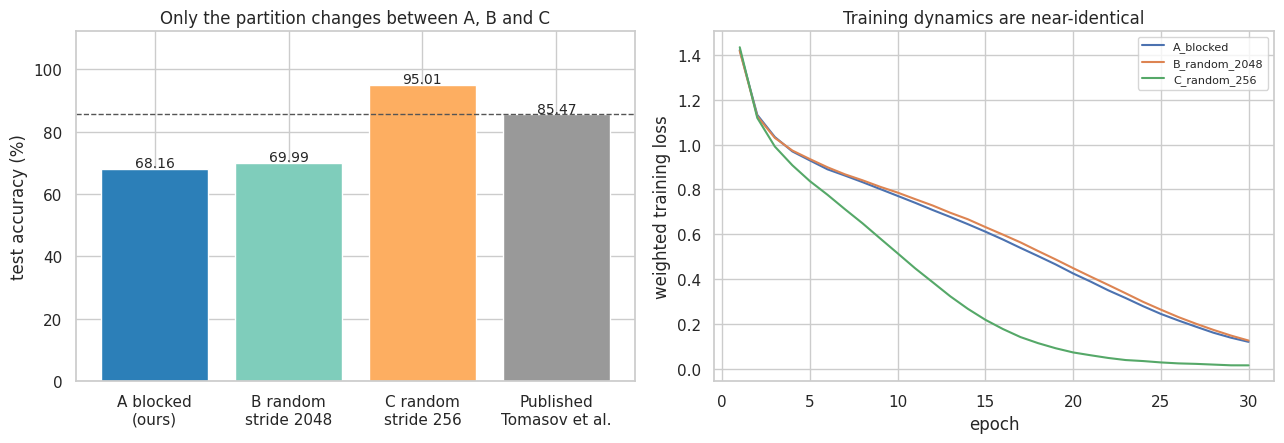

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
nl = chr(10)

ax = axes[0]
labels = ["A blocked" + nl + "(ours)", "B random" + nl + "stride 2048",
          "C random" + nl + "stride 256", "Published" + nl + "Tomasov et al."]
vals = [a_acc, b_acc, c_acc, PUB_ACC]
colours = ["#2c7fb8", "#7fcdbb", "#fdae61", "#999999"]
bars = ax.bar(labels, vals, color=colours)
for bar, v in zip(bars, vals):
    if v == v:
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.6, f"{v:.2f}",
                ha="center", fontsize=10)
ax.axhline(PUB_ACC, ls="--", lw=1, color="#555555")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, max(v for v in vals if v == v) * 1.18)
ax.set_title("Only the partition changes between A, B and C")

ax = axes[1]
for k, h in curves.items():
    ax.plot(range(1, len(h) + 1), h, label=k)
ax.set_xlabel("epoch")
ax.set_ylabel("weighted training loss")
ax.set_title("Training dynamics are near-identical")
ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(out_dir / "protocol_attribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. What this licenses the paper to say

Read `gap_decomposition.json`.

* If the **residual is small**, the sentence the reviewer challenged becomes a measured
  claim rather than an assertion: the reconstructed CNN matches the published figure once
  it is evaluated under the published protocol, and the shortfall under our protocol is
  the price of removing leakage. Quote the protocol and residual components explicitly in
  Section 4, and cite this notebook.
* If the **residual is large**, we must say so. The correct wording is that our
  reconstruction is a lower bound on their architecture's performance, that the baseline
  comparison is therefore indicative rather than exact, and that the leakage argument
  rests on arms A and B alone - which is still a valid within-study contrast, because A
  and B share every row.

Either way the A/B contrast stands on its own. It is the cleanest leakage measurement in
the study: one population, one model, one seed, two partitions.